# Clustering: objectives, geometry, algorithms, and evidence

## 1. Introduction and learning objectives

Clustering assigns structure to observations without using a supervised response during fitting. The structure depends on the representation, distance, objective and algorithm. A partition can be stable and visually persuasive without corresponding to a meaningful scientific category. This chapter makes those choices inspectable before the next chapters introduce probabilistic latent-variable models.

Derive and implement K-means updates, initialization and multiple starts; construct a small agglomerative hierarchy with four linkage rules; compute permutation-invariant and geometric assessments; and critique a primary-paper guarantee using exact tiny calculations. Required work uses manual NumPy and small generated arrays. No framework, external data download or GPU is needed.

**Prerequisites:** Stage 00 matrix/gradient and numerical tools and Stage 01 experimental design. Stage 02 is useful comparison experience, but no earlier notebook's live functions are required. Observations are rows of $X\in\mathbb R^{n\times d}$. Cluster IDs are integer names, not ordered targets. Notation and conventions below are part of the implementation contract.

## 2. Prerequisites and mathematical foundations

For centers $\mu_0,\ldots,\mu_{k-1}\in\mathbb R^d$ and assignments $z_i\in\{0,\ldots,k-1\}$, define the **sum** of squared Euclidean distances
$$J(z,\mu)=\sum_{i=1}^n\|x_i-\mu_{z_i}\|_2^2,\qquad \Phi(\mu)=\sum_i\min_j\|x_i-\mu_j\|_2^2.$$
Neither expression divides by $n$. Mean squared quantization distortion is $\Phi/n$ and is useful when reporting a separate probe sample with a different size. This objective is not classification error, a normalized likelihood or a probability-calibration measure.

Feature scaling changes Euclidean geometry. Multiplying coordinate $j$ by $s_j$ weights its squared contribution by $s_j^2$. Centering all observations by the same vector leaves pairwise Euclidean distances unchanged; anisotropic rescaling generally does not. If a trained representation will be applied to new observations, fit preprocessing on training data and reuse it. Scaling by a statistic computed from the probe changes that procedure.

K-means uses means because it minimizes squared Euclidean loss. Replacing the distance with Manhattan distance while keeping the same update does not preserve this derivation: coordinate medians minimize absolute deviations. Cosine, categorical, graph or learned-representation distances need their own objective and prototype reasoning. A name such as “similarity” does not make these geometries interchangeable.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 03.01.01 — Specify a clustering claim before choosing an algorithm

**Type:** Conceptual · **Answer:** Markdown

Describe a plausible two-feature study in which changing feature units changes a K-means partition. Explain the difference between a cluster ID, a class label, a centroid and a semantic category. Can an unlabeled algorithm be fitted and still have its design selected using labels?

**Expected outcome:** a concrete units/representation example and an explicit boundary between fitting and model-selection information.

**Your response to Exercise 03.01.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.01.01**

An algorithm can avoid labels inside its update and still use them indirectly through selection of features, distance, cluster count or the best run.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.01.01**

For example, a study mixing a physical length and a monetary amount gives different Euclidean weights when dollars become cents without a justified rescaling. A cluster ID only names a partition element; a centroid is its squared-loss prototype. Neither is automatically a known response category or a semantic concept. Choosing representations or cluster count to maximize agreement with known classes uses supervised information during selection even if the internal update reads only $X$. State that use and reserve a separate evaluation if the claim concerns prediction of those labels. Unlabeled fitting alone does not establish an unsupervised discovery protocol.

</details>

## 3. Theoretical development and worked examples

### Alternating minimization and its exact scope

For fixed centers, assign each point to a nearest center, choosing the smaller center index on a computed tie. For fixed assignments, a nonempty cluster $C$ has mean $\bar x_C$, and
$$\sum_{i\in C}\|x_i-\mu\|^2=\sum_{i\in C}\|x_i-\bar x_C\|^2+|C|\|\mu-\bar x_C\|^2.$$
Its gradient is $2\sum_{i\in C}(\mu-x_i)$ and Hessian $2|C|I$. The mean minimizes this block objective; a nonempty-cluster mean is unique. There is no extra observation average. Alternate these two block operations to obtain Lloyd's algorithm. Each operation cannot increase the objective in exact arithmetic.

A nonincreasing objective alone does not prove finite termination, a strict local minimum or global optimality. The implementation below stops when assignments stabilize under its explicit rules, or returns an unfinished flag at its iteration budget. A stable result may be a poor local solution. Empty-cluster rules and ties must be included in any stronger convergence argument.

An empty cluster has no mean. The default rule recomputes nonempty means and reseeds each empty center at a farthest point from the already placed nonempty/reseeded centers, using the smallest row index on a tie. The new assignment still cannot increase the old-assignment objective: empty centers had no assigned contribution, and adding a freely placed center cannot increase a nearest-center minimum. An alternative `keep` rule retains old empty centers and reports them. Assignment stability under that rule can leave fewer occupied clusters than requested; it is not a claim that $k$ meaningful groups were found.

**Hand Lloyd step:** $X=(0,2,8,10)$ and initial centers $(0,8)$ give assignments $(0,0,1,1)$ and potential $8$. Updating to $(1,9)$ keeps those assignments and gives potential $4$. For the first cluster alone, $J_C(\mu)=\mu^2+(2-\mu)^2$ has gradient $4\mu-4$ and minimum $2$ at $\mu=1$.

### Initialization and bounded multiple starts

Uniform random initialization samples distinct **row indices** without replacement; duplicate row values can still give duplicate centers. K-means++ first chooses one row uniformly, then samples a next row with probability proportional to its squared distance $D_i^2$ from the closest chosen center. Its probabilities describe records, so duplicate values retain their multiplicity. Reject $k$ larger than the number of distinct feature rows in these presets.

Use multiple declared starts, retain each run's seed, cost, status and effective cluster count, and choose the first lowest training potential. Equal start counts control search effort, not equal initial centers or wall time. A lower local cost at a larger $k$ is not itself evidence of more meaningful structure: the global optimum distortion is nonincreasing with additional centers even for a single continuous distribution.

### Hierarchical linkage and Ward's units

Agglomerative clustering begins with singleton clusters and repeatedly merges a closest pair under a declared cluster dissimilarity. For Euclidean point distances $d_{ij}=\|x_i-x_j\|$, single linkage takes $\min_{i\in A,j\in B}d_{ij}$, complete linkage takes the maximum, and average linkage takes the mean of **all** $|A||B|$ cross-cluster distances. An unweighted mean of two previously aggregated cluster means need not be this average.

Ward's rule instead chooses the smallest increase in within-cluster SSE:
$$\Delta_W(A,B)=\frac{|A||B|}{|A|+|B|}\|\bar x_A-\bar x_B\|^2.$$
Derive it from the mean decomposition. This chapter stores **$\Delta_W$ itself as the merge height**, in squared-feature units. Some software uses a transformed distance such as $\sqrt{2\Delta_W}$; heights are not interchangeable without stating the convention. Ward's derivation requires Euclidean squared-loss geometry, not an arbitrary dissimilarity matrix.

**Hand hierarchy:** for $(0,2,8,10)$, exact ties merge original indices $(0,1)$ first, then $(2,3)$. The final single/complete/average heights are $6,10,8$ respectively. Ward heights are $2,2,64$, whose sum $68$ equals the SSE around the grand mean $5$. Cutting each hierarchy at two groups gives $\{0,2\}$ and $\{8,10\}$. The same example shows why a height-axis label needs a metric and unit.

### Assessment is another model choice

For a point in a non-singleton cluster, let $a_i$ be mean Euclidean distance to its other cluster members and $b_i$ the minimum mean distance to a different cluster. Silhouette is $s_i=(b_i-a_i)/\max(a_i,b_i)$. We set singleton scores to zero and zero-denominator scores to zero, and require between two and $n-1$ occupied groups. This criterion favors a particular compact/separated geometry, not universal scientific validity.

For two partitions on the same observations, adjusted Rand index (ARI) compares co-assigned pairs while accounting for the fixed-marginal random-partition expectation. If $S=\sum_{ab}\binom{n_{ab}}2$, $A=\sum_a\binom{n_{a\cdot}}2$, $B=\sum_b\binom{n_{\cdot b}}2$ and $T=\binom n2$,
$$\mathrm{ARI}=\frac{S-AB/T}{(A+B)/2-AB/T}.$$
Identical partitions up to renaming give one; the value can be negative. The trivial matching all-singleton/all-one-group cases and a single observation are defined as one here. Perfect agreement between two trivial partitions is not evidence of useful structure. Stability ARI on a fixed probe is a comparison of fitted procedures, not a posterior probability or confidence interval.

### Exercise 03.01.02 — Derive the update, pairwise identity and Ward cost

**Type:** Mathematical · **Answer:** Markdown

Derive the centroid gradient/Hessian and mean decomposition. Show $\sum_i\|x_i-\bar x\|^2=(2m)^{-1}\sum_{i,j}\|x_i-x_j\|^2$ for $m$ points, then derive the Ward merge formula. Explain what changes if the pairwise expression divides by $m$ instead.

**Expected outcome:** correct factors, explicit nonempty-cluster assumption, and Ward's squared-feature units.

**Your response to Exercise 03.01.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.01.02**

Expand pairwise squared norms, remembering that the double sum includes both ordered pairs and zero diagonal terms.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.01.02**

The derivative is $2m\mu-2\sum_i x_i$ and Hessian $2mI$ for $m>0$. Expanding around $\bar x$ removes the cross term because residuals sum to zero. The ordered pairwise sum is $2m\sum_i\|x_i\|^2-2\|\sum_i x_i\|^2$, hence twice $m$ times the centered SSE. Using divisor $m$ instead of $2m$ doubles that objective; its minimizer is unchanged but gradients and reported increases scale by two. For disjoint clusters, substituting the weighted merged mean into the decomposition yields $m_A m_B/(m_A+m_B)$ times squared mean separation. Ward's stored cost here is that actual SSE increase.

</details>

### Exercise 03.01.03 — Reproduce a Lloyd step and four linkage conventions

**Type:** Numerical · **Answer:** Markdown

Compute the hand step's assignments, initial/final potential, occupied-cluster means and first-cluster gradient. Reconstruct the three merges for single, complete, average and Ward linkage, including deterministic ties. Check that Ward increments sum to grand-mean SSE.

**Expected outcome:** potentials $8,4$, means $1,9$, final heights $6,10,8,64$ and total Ward SSE $68$.

**Your response to Exercise 03.01.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.01.03**

The cross distances between $\{0,2\}$ and $\{8,10\}$ are $8,10,6,8$.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.01.03**

Initial nearest-center squared distances are $(0,4,0,4)$; at means $(1,9)$ they are all one. The first-cluster gradient is $4\mu-4$, zero at one. The cross-distance minimum, maximum and mean are $6,10,8$. Each first Ward merge has cost $(1\cdot1/2)2^2=2$. The final groups have size two and means one/nine, so their merge costs $(2\cdot2/4)8^2=64$. Adding $2+2+64$ yields $68$, matching $25+9+9+25$. Exact tie order is original pair $(0,1)$, then $(2,3)$; near floating ties are not promised identical across all arithmetic environments.

</details>

## 4. Guided exercises

### Exercise 03.01.04 — Implement direct distances and deterministic assignments

**Type:** Programming · **Answer:** Code

Implement `cluster_squared_distances` and `assign_clusters`. Accumulate squared coordinate differences without a three-dimensional tensor or a cancellation-prone norm expansion. Support empty query arrays, reject malformed/nonfinite inputs, and choose the smallest center index on a computed tie. Verify large-offset coordinates against scalar differences.

**Expected outcome:** correct shapes and distances, explicit range failures and assignments independent of query-block size.

In [ ]:
# Your code for Exercise 03.01.04.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.01.04**

The returned matrix still costs $8nk$ bytes; a block controls scratch memory, not that output size.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.01.04**

The helper is deliberately visible and reused only by later snippets in this chapter. Arithmetic overflow raises an error rather than becoming a fabricated distance. Squared-distance underflow remains a floating-point limitation; the seeder diagnoses a zero numerical potential when distinct values cannot be separated in this representation.

~~~python
def cluster_features(X, allow_empty=False):
    X = np.asarray(X,dtype=float)
    if X.ndim != 2 or X.shape[1] == 0 or (not allow_empty and len(X) == 0) or not np.isfinite(X).all():
        raise ValueError('finite (n, d) features with d >= 1 required')
    return X

def cluster_squared_distances(X, centers, block=64):
    X = cluster_features(X,allow_empty=True); centers = cluster_features(centers)
    if X.shape[1] != centers.shape[1]:
        raise ValueError('feature widths must match')
    if isinstance(block,(bool,np.bool_)) or not isinstance(block,(int,np.integer)) or block < 1:
        raise ValueError('positive integer query block required')
    squared = np.zeros((len(X),len(centers)))
    with np.errstate(over='raise',invalid='raise'):
        for start in range(0,len(X),block):
            stop = min(start+block,len(X))
            for feature in range(X.shape[1]):
                difference = X[start:stop,feature,None]-centers[None,:,feature]
                squared[start:stop] += difference*difference
    return squared

def assign_clusters(X, centers, block=64):
    squared = cluster_squared_distances(X,centers,block)
    labels = np.argmin(squared,axis=1)
    return labels,squared[np.arange(len(squared)),labels]

assert np.array_equal(assign_clusters([[1.]],[[0.],[2.]])[0],[0])
~~~

</details>

### Exercise 03.01.05 — Seed centers with declared sampling probabilities

**Type:** Programming · **Answer:** Code

Implement `seed_kmeans(X, k, method='plus_plus', seed=250)`. Support uniform row-index sampling without replacement and K-means++ D-squared sampling. Return selected indices and copied centers. Require $k$ no larger than the distinct-row count; preserve duplicate-record multiplicity. Stabilize the probability normalization without silently replacing a zero numerical potential with another distribution.

**Expected outcome:** seeded reproducibility, exact tiny conditional probabilities and a visible underflow/zero-potential failure.

In [ ]:
# Your code for Exercise 03.01.05.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.01.05**

Divide squared weights by their maximum before summing; this preserves probabilities while avoiding an overflowing normalization sum.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.01.05**

This depends on `cluster_features` and `cluster_squared_distances`. Uniform row indices can name identical vectors. K-means++ assigns zero probability to already represented values when squared distances are representable. Its theoretical distribution assumes those weights are calculated correctly; a machine-range failure should be reported.

~~~python
def seed_kmeans(X, k, method='plus_plus', seed=250):
    X = cluster_features(X)
    if isinstance(k,(bool,np.bool_)) or not isinstance(k,(int,np.integer)) or not 1 <= k <= len(np.unique(X,axis=0)):
        raise ValueError('integer k must fit the number of distinct rows')
    rng = np.random.default_rng(seed)
    if method == 'random':
        chosen = rng.choice(len(X),k,replace=False).tolist()
    elif method == 'plus_plus':
        chosen = [int(rng.integers(len(X)))]
        closest = cluster_squared_distances(X,X[chosen])[:,0]
        while len(chosen) < k:
            maximum = float(closest.max())
            if maximum <= 0:
                raise FloatingPointError('zero representable seeding potential before k centers')
            weights = closest/maximum
            index = int(rng.choice(len(X),p=weights/weights.sum()))
            chosen.append(index)
            closest = np.minimum(closest,cluster_squared_distances(X,X[[index]])[:,0])
    else:
        raise ValueError('method must be random or plus_plus')
    indices = np.array(chosen,dtype=int)
    return X[indices].copy(),indices
~~~

</details>

## 5. Implementation challenges

The algorithmic budgets are part of the experiment. Distances use two-dimensional output/scratch matrices. Hierarchical fitting is intentionally capped at 80 rows because its auditable exhaustive merge search is roughly cubic; silhouette is capped at 400 rows because it uses a complete pairwise matrix. K-means experiments below use at most 180 fitting rows and five centers. Faster data structures are a later optimization, after independent correctness checks.

### Exercise 03.01.06 — Fit Lloyd updates with honest empty-cluster and stopping rules

**Type:** Programming · **Answer:** Code

Implement `fit_kmeans` with seeded or explicit initial centers, at most 500 iterations, the two named empty policies, and traces of centers/potential. Also implement `centroid_sse_derivatives` for a fixed nonempty cluster and a candidate center. Return its summed loss, gradient and Hessian. The fitter returns labels assigned to the returned centers, effective occupied-cluster count and a flag meaning assignments stabilized. Keep a budget-exhausted run explicitly unfinished. Verify centroid derivatives for fixed assignments using an independent scalar objective.

**Expected outcome:** nonincreasing potential within numerical tolerance, consistent output states, empty-event records, hand convergence and a deliberate short-budget failure.

In [ ]:
# Your code for Exercise 03.01.06.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.01.06**

Update nonempty means first. Reseed empty centers using distances to the newly placed centers, then reassign all observations before checking stability.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.01.06**

This depends on the preceding distance/seed definitions. Convergence here means the assignments no longer change under the declared update; it does not prove global optimality. The `keep` policy may stabilize with unused slots. The default farthest reseeding preserves nonincrease in the exact block argument and records each chosen row.

~~~python
def centroid_sse_derivatives(X, center):
    X = cluster_features(X); center = np.asarray(center,dtype=float)
    if center.shape != (X.shape[1],) or not np.isfinite(center).all():
        raise ValueError('one finite center vector of width d required')
    with np.errstate(over='raise',invalid='raise'):
        residual = center-X
        return float(np.sum(residual*residual)),2*residual.sum(axis=0),2*len(X)*np.eye(X.shape[1])

def fit_kmeans(X, k, init='plus_plus', seed=250, max_steps=100, empty='farthest', block=64):
    X = cluster_features(X)
    if isinstance(k,(bool,np.bool_)) or not isinstance(k,(int,np.integer)) or not 1 <= k <= len(np.unique(X,axis=0)):
        raise ValueError('integer k must fit the distinct-row count')
    if isinstance(max_steps,(bool,np.bool_)) or not isinstance(max_steps,(int,np.integer)) or not 1 <= max_steps <= 500 or empty not in ('keep','farthest'):
        raise ValueError('iteration budget 1..500 and a known empty policy required')
    if isinstance(init,str):
        centers,indices = seed_kmeans(X,k,init,seed)
    else:
        centers = cluster_features(init).copy(); indices = None
        if centers.shape != (k,X.shape[1]):
            raise ValueError('initial center shape must be (k, d)')
    labels,distances = assign_clusters(X,centers,block)
    with np.errstate(over='raise',invalid='raise'):
        cost = float(distances.sum())
    history = [cost]; trace = [centers.copy()]; events = []; converged = False
    for iteration in range(1,max_steps+1):
        updated = centers.copy(); counts = np.bincount(labels,minlength=k)
        with np.errstate(over='raise',invalid='raise'):
            for c in np.flatnonzero(counts):
                updated[c] = X[labels == c].mean(axis=0)
        missing = np.flatnonzero(counts == 0); reseeded = []
        if len(missing) and empty == 'farthest':
            closest = cluster_squared_distances(X,updated[counts > 0],block).min(axis=1)
            for c in missing:
                row = int(np.argmax(closest))
                if closest[row] <= 0:
                    raise FloatingPointError('empty center cannot be separated numerically')
                updated[c] = X[row]; reseeded.append(row)
                closest = np.minimum(closest,cluster_squared_distances(X,updated[[c]],block)[:,0])
        if len(missing):
            events.append(dict(iteration=iteration,clusters=missing.tolist(),policy=empty,rows=reseeded))
        new_labels,new_distances = assign_clusters(X,updated,block)
        with np.errstate(over='raise',invalid='raise'):
            new_cost = float(new_distances.sum())
        if new_cost > cost+1e-10*max(1.,abs(cost)):
            raise FloatingPointError('Lloyd objective increased beyond roundoff tolerance')
        stable = np.array_equal(new_labels,labels)
        centers,labels,cost = updated,new_labels,new_cost
        history.append(cost); trace.append(centers.copy())
        if stable:
            converged = True; break
    return dict(centers=centers,labels=labels,inertia=cost,inertia_history=np.array(history),
                center_history=np.array(trace),iterations=iteration,converged=converged,
                effective_clusters=len(np.unique(labels)),empty_events=events,initial_indices=indices)

demo_lloyd = fit_kmeans([[0.],[2.],[8.],[10.]],2,init=[[0.],[8.]])
assert demo_lloyd['converged'] and np.allclose(demo_lloyd['centers'],[[1.],[9.]])
assert np.allclose(demo_lloyd['inertia_history'],[8.,4.])
~~~

</details>

### Exercise 03.01.07 — Retain a bounded multiple-start search

**Type:** Programming · **Answer:** Code

Implement `kmeans_restarts` with 1–32 independent child seeds, fixed method/iteration policy, records for every run and first-minimum training selection. Retain unfinished runs and their status instead of silently changing the budget. Keep external labels and probe outcomes out of this selector.

**Expected outcome:** deterministic seeds and winner, complete run records, no unseen-outcome argument and a bounded work count.

In [ ]:
# Your code for Exercise 03.01.07.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.01.07**

Use a seed sequence to generate child seeds; selecting the lowest observed cost is a search policy, not proof of the global optimum.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.01.07**

This depends on `fit_kmeans`. The returned winner may be a budget-limited fitted predictor if it has the best observed cost; its flag remains visible. Increasing start count has a compute cost and should be declared before claiming a matched comparison.

~~~python
def kmeans_restarts(X, k, starts=8, method='plus_plus', seed=251, max_steps=100, empty='farthest'):
    if isinstance(starts,(bool,np.bool_)) or not isinstance(starts,(int,np.integer)) or not 1 <= starts <= 32:
        raise ValueError('integer start count 1..32 required')
    seeds = [int(child.generate_state(1)[0]) for child in np.random.SeedSequence(seed).spawn(starts)]
    models = [fit_kmeans(X,k,method,child,max_steps,empty) for child in seeds]
    records = [dict(seed=child,inertia=model['inertia'],converged=model['converged'],
                    iterations=model['iterations'],effective_clusters=model['effective_clusters'],
                    empty_events=len(model['empty_events'])) for child,model in zip(seeds,models)]
    best = min(range(starts),key=lambda index:records[index]['inertia'])
    return models[best],records,best
~~~

</details>

### Exercise 03.01.08 — Build four small agglomerative hierarchies

**Type:** Programming · **Answer:** Code

Implement `agglomerative_linkage` for single, complete, average and Ward, with at most 80 observations. Store child IDs, declared merge height and member count. Original rows have IDs $0,\ldots,n-1$ and merge $t$ gets ID $n+t$. Resolve exact cost ties lexicographically by child IDs. Verify heights against independent member-level calculations.

**Expected outcome:** complete merge history, counts and correct all-pair average/Ward weighting, including duplicate and tie cases.

In [ ]:
# Your code for Exercise 03.01.08.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.01.08**

Cache original point distances for the first three methods. Ward costs use cluster sizes and means, with height equal to the SSE increase here.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.01.08**

This depends on the distance helper. Its exhaustive search prioritizes clarity over optimized linkage recurrences. Do not interpret the resulting array with another library's Ward convention without conversion. Exact ties depend on original row IDs; a visually rotated dendrogram does not change its partition hierarchy.

~~~python
def agglomerative_linkage(X, method='average'):
    X = cluster_features(X); n = len(X)
    if not 2 <= n <= 80 or method not in ('single','complete','average','ward'):
        raise ValueError('2..80 rows and a supported linkage required')
    distances = np.sqrt(cluster_squared_distances(X,X))
    members = {i:np.array([i],dtype=int) for i in range(n)}
    means = {i:X[i].copy() for i in range(n)}; rows = []
    with np.errstate(over='raise',invalid='raise'):
        for t in range(n-1):
            active = sorted(members); best = None
            for ai,a in enumerate(active):
                for b in active[ai+1:]:
                    A,B = members[a],members[b]
                    if method == 'ward':
                        difference = means[a]-means[b]
                        cost = len(A)*len(B)/(len(A)+len(B))*np.sum(difference*difference)
                    else:
                        cross = distances[np.ix_(A,B)]
                        cost = cross.min() if method == 'single' else (cross.max() if method == 'complete' else cross.mean())
                    candidate = (float(cost),a,b)
                    if best is None or candidate < best:
                        best = candidate
            cost,a,b = best; A,B = members[a],members[b]; size = len(A)+len(B)
            rows.append([a,b,cost,size]); new = n+t
            members[new] = np.r_[A,B]
            means[new] = (len(A)/size)*means[a]+(len(B)/size)*means[b]
            del members[a],members[b],means[a],means[b]
    return dict(linkage=np.array(rows,dtype=float),method=method,n_samples=n,
                height_convention='SSE increase' if method == 'ward' else 'Euclidean linkage distance')
~~~

</details>

### Exercise 03.01.09 — Cut a hierarchy without treating IDs as semantic labels

**Type:** Programming · **Answer:** Code

Implement `cut_linkage(model, k)`. Replay its first $n-k$ merges, preserve every observation once, and label the remaining groups in increasing order of their smallest original row index. Check parent/member validity in the consumed prefix. Explain why differently named cluster IDs can encode the same partition.

**Expected outcome:** nested valid partitions, all $k$ groups occupied, correct boundary cuts and rejection of malformed merge prefixes.

In [ ]:
# Your code for Exercise 03.01.09.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.01.09**

Only active clusters can be merged. Newly created IDs follow the stored iteration order.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.01.09**

This consumes the preceding model format, not a generic external dendrogram. Canonical labels simplify comparison, but a permutation-invariant metric is still needed across unrelated fits. A $k$-cut groups these observed rows; it does not automatically supply a prediction rule for unseen observations.

~~~python
def cut_linkage(model, k):
    n = model['n_samples']; tree = np.asarray(model['linkage'])
    if isinstance(k,(bool,np.bool_)) or not isinstance(k,(int,np.integer)) or not 1 <= k <= n or tree.shape != (n-1,4) or not np.isfinite(tree).all():
        raise ValueError('valid linkage shape and integer cut 1..n required')
    members = {i:[i] for i in range(n)}
    for t,row in enumerate(tree[:n-k]):
        a,b = int(row[0]),int(row[1])
        if a != row[0] or b != row[1] or a == b or a not in members or b not in members:
            raise ValueError('merge must join two distinct active child IDs')
        joined = members.pop(a)+members.pop(b)
        if row[3] != len(joined):
            raise ValueError('merge member count is inconsistent')
        members[n+t] = joined
    labels = np.empty(n,dtype=int)
    for label,indices in enumerate(sorted(members.values(),key=min)):
        labels[indices] = label
    return labels

demo_hierarchy = agglomerative_linkage([[0.],[2.],[8.],[10.]],'ward')
assert np.allclose(demo_hierarchy['linkage'][:,2],[2.,2.,64.])
assert np.array_equal(cut_linkage(demo_hierarchy,2),[0,0,1,1])
~~~

</details>

### Exercise 03.01.10 — Compute intrinsic geometry and partition agreement

**Type:** Programming · **Answer:** Code

Implement `silhouette_samples` with its stated singleton/zero-distance conventions and `adjusted_rand_index` for integer-named partitions. Require 2 to $n-1$ groups for silhouette, and at most 400 rows for its full pairwise calculation. Use exact integer pair counts for ARI rather than comparing raw labels or allocating all observation pairs.

**Expected outcome:** hand silhouettes, singleton and duplicate behavior, arbitrary label-renaming invariance and meaningful degenerate-case conventions.

In [ ]:
# Your code for Exercise 03.01.10.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.01.10**

For ARI, multiplying numerator/denominator by $2T$ allows exact integer arithmetic until the final ratio.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.01.10**

Silhouette depends on the same Euclidean representation used for its distances. ARI uses a sparse contingency count and fixed-marginal chance adjustment; it is not an independence test or a calibrated uncertainty measure. The zero-denominator ARI cases are matching trivial partitions and receive one under this declared convention.

~~~python
def cluster_partition(labels, n):
    labels = np.asarray(labels)
    if labels.shape != (n,) or not np.issubdtype(labels.dtype,np.integer):
        raise ValueError('one integer cluster name per observation required')
    return labels

def silhouette_samples(X, labels):
    X = cluster_features(X); labels = cluster_partition(labels,len(X))
    classes = np.unique(labels)
    if len(X) > 400 or not 2 <= len(classes) <= len(X)-1:
        raise ValueError('silhouette requires <=400 rows and 2..n-1 groups')
    distances = np.sqrt(cluster_squared_distances(X,X)); result = np.zeros(len(X))
    for i in range(len(X)):
        own = labels == labels[i]; count = int(own.sum())
        if count == 1:
            continue
        a = distances[i,own].sum()/(count-1)
        b = min(float(distances[i,labels == c].mean()) for c in classes if c != labels[i])
        denominator = max(a,b)
        result[i] = (b-a)/denominator if denominator > 0 else 0.
    return result

def adjusted_rand_index(left, right):
    left = np.asarray(left); right = np.asarray(right)
    if left.ndim != 1 or len(left) == 0:
        raise ValueError('nonempty partitions required')
    left = cluster_partition(left,len(left)); right = cluster_partition(right,len(left))
    _,a = np.unique(left,return_inverse=True); _,b = np.unique(right,return_inverse=True)
    cells = {}
    for x,y in zip(a,b):
        key = (int(x),int(y)); cells[key] = cells.get(key,0)+1
    choose2 = lambda value: int(value)*(int(value)-1)//2
    S = sum(choose2(value) for value in cells.values())
    A = sum(choose2(value) for value in np.bincount(a)); B = sum(choose2(value) for value in np.bincount(b))
    T = choose2(len(left)); denominator = T*(A+B)-2*A*B
    return 1. if denominator == 0 else 2*(T*S-A*B)/denominator

assert adjusted_rand_index([0,0,1,1],[8,8,3,3]) == 1.
~~~

</details>

## 6. Experiments and visualizations

The default plots show **given hand calculations**, not an executable answer to a general fitting exercise. The Lloyd center move reduces the specified objective; the Ward diagram uses an explicitly labeled SSE-increase axis. The experiments below measure fitted procedures separately.

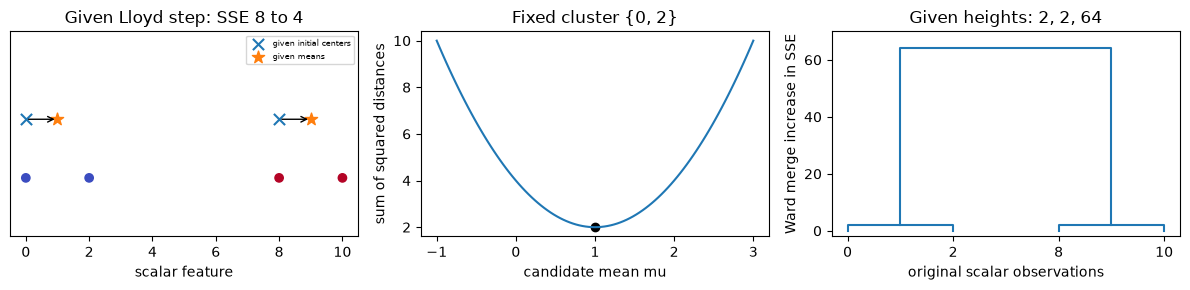

In [2]:
fig,axes = plt.subplots(1,3,figsize=(12,3))
demo_points = np.array([0.,2.,8.,10.])
axes[0].scatter(demo_points,np.zeros(4),c=[0,0,1,1],cmap='coolwarm')
axes[0].scatter([0,8],[.2,.2],marker='x',s=65,label='given initial centers')
axes[0].scatter([1,9],[.2,.2],marker='*',s=85,label='given means')
for old,new in ((0,1),(8,9)):
    axes[0].annotate('',xy=(new,.2),xytext=(old,.2),arrowprops=dict(arrowstyle='->'))
axes[0].set(xlabel='scalar feature',yticks=[],ylim=(-.2,.5),title='Given Lloyd step: SSE 8 to 4')
axes[0].legend(fontsize=6)
demo_mean_axis = np.linspace(-1,3,101)
demo_cluster_loss = demo_mean_axis**2+(2-demo_mean_axis)**2
axes[1].plot(demo_mean_axis,demo_cluster_loss)
axes[1].scatter([1],[2],color='black')
axes[1].set(xlabel='candidate mean mu',ylabel='sum of squared distances',title='Fixed cluster {0, 2}')
axes[2].plot([0,0,1,1],[0,2,2,0],color='tab:blue')
axes[2].plot([2,2,3,3],[0,2,2,0],color='tab:blue')
axes[2].plot([.5,.5,2.5,2.5],[2,64,64,2],color='tab:blue')
axes[2].set(xticks=range(4),xticklabels=['0','2','8','10'],xlabel='original scalar observations',
            ylabel='Ward merge increase in SSE',title='Given heights: 2, 2, 64',ylim=(-2,70))
fig.tight_layout(); plt.show()

### Exercise 03.01.11 — Compare initialization under a fixed search budget

**Type:** Experimental · **Answer:** Code

Generate 180 training and 120 independent probe observations from the declared three-blob mechanism below. Fit three centers with eight starts for each of uniform row-index and K-means++ initialization, 100 steps per start, and the default empty policy. Select by training potential only. Retain every run's seed, potential, stopping flag and effective cluster count. Report actual elapsed times, the selected training silhouette and probe mean distortion; plot fitted partitions and objective traces. Do not use generating-component labels to select a fit or claim that one method must win.

**Expected outcome:** a reproducible matched-start comparison, complete run/status records, and conclusions restricted to the observed data, representation and search budget.

In [ ]:
# Your code for Exercise 03.01.11.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.01.11**

The mixture weights are $(1/6,2/3,1/6)$ in both samples. Equal numbers of starts do not make initialization costs or total iterations identical.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.01.11**

This uses the preceding fitting, assignment and silhouette functions. Fixed component counts are declared in each sample; observations are drawn independently conditional on those allocations from one seeded stream. These are not random mixture-count draws. Component membership is not supplied to the fitter or selector. The printed values and plotted traces are produced by execution; do not substitute an assumed ranking. Probe distortion evaluates the selected quantizer on new rows. It does not establish the number of semantic classes or provide an unbiased comparison after repeatedly choosing designs on that same probe.

~~~python
from time import perf_counter

def clustering_blob_data(seed=250):
    rng = np.random.default_rng(seed)
    means = np.array([[-4.,0.],[0.,0.],[4.,0.]])
    scales = [.3,.6,.3]
    def draw(counts):
        return np.vstack([rng.normal(mean,scale,size=(count,2))
                          for mean,scale,count in zip(means,scales,counts)])
    return draw([30,120,30]),draw([20,80,20])

initial_train,initial_probe = clustering_blob_data()
initialization_results = {}
fig,axes = plt.subplots(1,3,figsize=(12,3.3))
for axis,method in zip(axes[:2],('random','plus_plus')):
    started = perf_counter()
    model,runs,winner = kmeans_restarts(initial_train,3,starts=8,method=method,seed=251,max_steps=100)
    seconds = perf_counter()-started
    probe_distortion = float(assign_clusters(initial_probe,model['centers'])[1].mean())
    silhouette = float(silhouette_samples(initial_train,model['labels']).mean())
    initialization_results[method] = dict(model=model,runs=runs,winner=winner,
        seconds=seconds,probe_distortion=probe_distortion,silhouette=silhouette)
    print(method,dict(seconds=seconds,winner=winner,train_SSE=model['inertia'],
        probe_mean_distortion=probe_distortion,silhouette=silhouette),runs)
    axis.scatter(*initial_train.T,c=model['labels'],s=12,cmap='viridis')
    axis.scatter(*model['centers'].T,c='black',marker='x',s=70)
    axis.set(title=method,xlabel='feature 1',ylabel='feature 2')
    axes[2].plot(model['inertia_history'],marker='.',label=method)
axes[2].set(title='Selected run only',xlabel='Lloyd update',ylabel='Training SSE')
axes[2].legend(); fig.tight_layout(); plt.show()
~~~

</details>

### Exercise 03.01.12 — Separate linkage changes from geometry changes

**Type:** Experimental · **Answer:** Code

Generate 48 rows with seed 252: 16 isotropic Gaussian draws of standard deviation $.3$ around each of $(-2,0),(0,1),(2,0)$. Stretch feature two by eight. Fit all four hierarchies in that raw geometry and in the geometry standardized using these 48 training rows only; cut each at three groups. Record group sizes, silhouette in the fitted geometry, root height with units, and actual fit time. Compare partitions with a three-center K-means fit in the same geometry. Display partitions on common original coordinates so a changed plot scale does not hide a changed assignment.

**Expected outcome:** eight auditable hierarchies and correctly scoped comparisons; neither cross-geometry scores nor incompatible height units are treated as a universal ranking.

In [ ]:
# Your code for Exercise 03.01.12.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.01.12**

Average linkage uses every cross pair. Ward uses squared distances between size-weighted means. A K-means partition is a comparator, not a ground-truth label set.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.01.12**

This depends on the preceding hierarchy, cut, assessment and restart functions. The raw transformation changes the metric before fitting. Training standardization defines a second metric; it does not restore an intrinsically correct one. Silhouettes describe their own geometries. ARI compares partitions on the same row identities and does not require matching their integer names. Linkage root heights have different meanings across methods, and every height changes with feature units. No generating-component labels enter this experiment's comparisons or selection.

~~~python
from time import perf_counter

geometry_rng = np.random.default_rng(252)
geometry_original = np.vstack([geometry_rng.normal(mean,.3,size=(16,2))
                              for mean in [(-2.,0.),(0.,1.),(2.,0.)]])
geometry_raw = geometry_original*np.array([1.,8.])
geometry_mean,geometry_scale = geometry_raw.mean(axis=0),geometry_raw.std(axis=0)
geometry_scaled = (geometry_raw-geometry_mean)/geometry_scale
geometry_results = []
fig,axes = plt.subplots(2,4,figsize=(12,6),sharex=True,sharey=True)
for row,(name,features) in enumerate([('raw stretched',geometry_raw),('standardized',geometry_scaled)]):
    comparator,comparator_runs,_ = kmeans_restarts(features,3,starts=8,seed=253)
    for column,method in enumerate(('single','complete','average','ward')):
        started = perf_counter(); hierarchy = agglomerative_linkage(features,method)
        elapsed = perf_counter()-started; partition = cut_linkage(hierarchy,3)
        record = dict(geometry=name,method=method,seconds=elapsed,
            sizes=np.bincount(partition).tolist(),silhouette=float(silhouette_samples(features,partition).mean()),
            root_height=float(hierarchy['linkage'][-1,2]),units=hierarchy['height_convention'],
            ARI_with_kmeans=adjusted_rand_index(partition,comparator['labels']),
            comparator_runs=comparator_runs)
        geometry_results.append(record); print(record)
        axes[row,column].scatter(*geometry_original.T,c=partition,s=14,cmap='viridis')
        axes[row,column].set(title=name+' / '+method,xlabel='original feature 1',ylabel='original feature 2')
fig.suptitle('Common display coordinates; fitting geometries differ')
fig.tight_layout(); plt.show()
~~~

</details>

### Exercise 03.01.13 — Challenge structure and stability claims with a null mechanism

**Type:** Experimental · **Answer:** Code

Draw 160 training and 120 independent probe rows from a single two-dimensional standard Gaussian, seed 254. Fit $k=2,3,4,5$ with eight starts each, seed 255, and at most 100 steps. Report selected training SSE, silhouette and all run statuses. For $k=3$, draw four row bootstraps with replacement using seed 256, fit each with four starts and seeds 257–260, and compare its assignments on the same fixed probe to the full-training fit using ARI. Record actual times and show the null sample and conditional stability values.

**Expected outcome:** measured geometric partitions of a one-component distribution, a complete finite-budget audit, and a clear distinction between conditional sensitivity and evidence of natural categories.

In [ ]:
# Your code for Exercise 03.01.13.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.01.13**

The global best distortion cannot increase with more centers, even for this null mechanism. Independently initialized finite fits need not attain those optima.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.01.13**

This uses the preceding fitter, assignment and assessment functions. Nothing in the fit requires distinct generating classes. Any appealing silhouette or reproducible subdivision still describes a partition of a continuous one-component mechanism. Bootstrap ARIs hold this probe fixed and vary an empirical training sample and optimizer starts. Four draws are an intentionally small sensitivity illustration, not a calibrated confidence interval. An all-one-group comparator would agree with itself perfectly while supplying no separated-cluster evidence; a stability number needs the procedure and scientific question beside it.

~~~python
from time import perf_counter

null_rng = np.random.default_rng(254)
null_train = null_rng.normal(size=(160,2)); null_probe = null_rng.normal(size=(120,2))
null_results = {}; null_started = perf_counter()
for k in (2,3,4,5):
    model,runs,winner = kmeans_restarts(null_train,k,starts=8,seed=255,max_steps=100)
    null_results[k] = dict(model=model,runs=runs,winner=winner,
        silhouette=float(silhouette_samples(null_train,model['labels']).mean()))
    print('null',k,model['inertia'],null_results[k]['silhouette'],runs)
null_baseline = assign_clusters(null_probe,null_results[3]['model']['centers'])[0]
bootstrap_rng = np.random.default_rng(256); null_stability = []
for trial in range(4):
    sampled = bootstrap_rng.integers(len(null_train),size=len(null_train))
    model,runs,winner = kmeans_restarts(null_train[sampled],3,starts=4,seed=257+trial,max_steps=100)
    probe_partition = assign_clusters(null_probe,model['centers'])[0]
    record = dict(trial=trial,ARI=adjusted_rand_index(null_baseline,probe_partition),runs=runs,winner=winner)
    null_stability.append(record); print('bootstrap',record)
print('null study seconds',perf_counter()-null_started)
fig,axes = plt.subplots(1,2,figsize=(9,3))
axes[0].scatter(*null_train.T,c=null_results[3]['model']['labels'],s=12,cmap='viridis')
axes[0].set(title='One Gaussian, fitted k=3',xlabel='feature 1',ylabel='feature 2')
axes[1].plot(range(4),[record['ARI'] for record in null_stability],marker='o')
axes[1].set(title='Fixed-probe bootstrap sensitivity',xlabel='bootstrap draw',ylabel='ARI versus full fit',ylim=(-.1,1.05))
fig.tight_layout(); plt.show()
~~~

</details>

## 7. Interpretation and critical analysis

### Bounded primary-source study

Read [Arthur and Vassilvitskii, K-means++, algorithm and Theorem 1.1](https://theory.stanford.edu/~sergei/papers/kMeansPP-soda.pdf) after implementing the seeder. Translate its potential into this chapter's SSE and audit D-squared probabilities on a tiny data set. The selected statement bounds **expected initialization potential** by $8(\ln k+2)\Phi_{OPT}$; nonincreasing Lloyd updates preserve that expectation bound. It does not promise that every initialization attains that bound or finds the global optimum. The study does not reproduce the full approximation proof or original benchmarks.

For an alternative explanation of linkage and assessment, see [Modern Statistics for Modern Biology, §§5.6–5.7](https://web.stanford.edu/class/bios221/book/05-chap.html). Audit objective units when comparing sources. A pairwise objective with divisor $m$ is twice the centroid SSE with divisor $2m$; proportional objectives can share a minimizer while differing in reported values and gradients.

### Exercise 03.01.14 — Audit an expectation guarantee with a bounded exact oracle

**Type:** Programming · **Answer:** Code

Read Arthur and Vassilvitskii's K-means++ algorithm and Theorem 1.1. For at most ten rows, enumerate all nonempty two-group partitions with the first row assigned to group zero and compute their centroid SSEs independently of Lloyd's algorithm. Separately enumerate every possible first and second K-means++ row selection with its exact sampling weight. Apply both calculations to $X=(0,0,2,10)$. Compare the global optimum, expected initial potential, and the possible initial centers $(0,2)$ with the stated expectation bound. Explain what changes after Lloyd updates.

**Expected outcome:** optimum $8/3$, expected initial potential $10234/1287$, positive probability of initial potential $64$, and a correctly scoped reading of the theorem.

In [ ]:
# Your code for Exercise 03.01.14.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.01.14**

Duplicate zero records have distinct selection probabilities. After selecting a zero, the conditional probability of selecting two is $4/(4+100)=1/26$. The expectation bound is not an upper bound on every random outcome.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.01.14**

This bounded oracle is exponential and is deliberately not a replacement for a scalable fitter. The partition objective below recomputes means directly without calling the Lloyd implementation. The separate seed expectation uses the chapter's distance helper and sums over row identities, so repeated values preserve multiplicity. Independent tests also compute the small expectation with rational scalar arithmetic.

For the worked data, the optimum joins $(0,0,2)$ at mean $2/3$ and leaves ten alone, giving $8/3$. The possible unordered coordinate pairs $(0,2),(0,10),(2,10)$ have probabilities $11/234,575/858,28/99$ and potentials $64,4,8$. Their weighted mean is $10234/1287\approx7.952$. The bound $8(\ln2+2)(8/3)\approx57.454$ is larger than this expectation, while the possible initial potential $64$ exceeds the bound. There is no contradiction: the theorem controls the expectation over initialization. Lloyd updates from $(0,2)$ can repair this tiny case, so the counterexample concerns the initial potential, not a claim that the same bad value persists after optimization. This calculation checks one instance and the distinction between two claims; it does not prove the general theorem.

~~~python
def tiny_two_means_optimum(X):
    X = cluster_features(X); n = len(X)
    if not 2 <= n <= 10:
        raise ValueError('oracle is bounded to 2..10 rows')
    best = None
    for mask in range(1,1 << (n-1)):
        labels = np.r_[0,[(mask >> bit) & 1 for bit in range(n-1)]]
        cost = 0.
        with np.errstate(over='raise',invalid='raise'):
            for c in (0,1):
                members = X[labels == c]
                cost += float(np.sum((members-members.mean(axis=0))**2))
        if best is None or cost < best['inertia']:
            best = dict(inertia=cost,labels=labels.copy())
    return best

def exact_two_seed_potential(X):
    X = cluster_features(X); n = len(X)
    if not 2 <= n <= 10 or len(np.unique(X,axis=0)) < 2:
        raise ValueError('2..10 rows with at least two distinct values required')
    squared = cluster_squared_distances(X,X); expected = 0.; total_probability = 0.
    for first in range(n):
        maximum = float(squared[:,first].max())
        if maximum <= 0:
            raise FloatingPointError('zero numerical seeding potential')
        weights = squared[:,first]/maximum; probabilities = weights/weights.sum()
        for second in range(n):
            if probabilities[second] > 0:
                probability = float(probabilities[second])/n
                with np.errstate(over='raise',invalid='raise'):
                    potential = float(np.minimum(squared[:,first],squared[:,second]).sum())
                expected += probability*potential; total_probability += probability
    return dict(expected_potential=expected,total_probability=total_probability)

oracle_data = np.array([[0.],[0.],[2.],[10.]])
oracle_optimum = tiny_two_means_optimum(oracle_data)
oracle_expectation = exact_two_seed_potential(oracle_data)
oracle_bound = 8*(np.log(2)+2)*oracle_optimum['inertia']
oracle_possible = float(assign_clusters(oracle_data,[[0.],[2.]])[1].sum())
print('tiny optimum / seed expectation / expectation bound / possible initial cost',
      oracle_optimum,oracle_expectation,oracle_bound,oracle_possible)
assert np.isclose(oracle_optimum['inertia'],8/3)
assert np.isclose(oracle_expectation['expected_potential'],10234/1287)
assert oracle_possible > oracle_bound > oracle_expectation['expected_potential']
~~~

</details>

### Exercise 03.01.15 — State what a stable or high-silhouette partition establishes

**Type:** Critical · **Answer:** Markdown

Two procedures agree strongly on a fixed probe, and one gives a high silhouette. Explain what evidence this supplies and what is missing before claiming discovery of natural or semantic classes. Include feature scaling, a one-Gaussian null mechanism, external-label selection and the fact that a hierarchy has no automatic unseen-point prediction rule.

**Expected outcome:** separate geometry, algorithmic sensitivity, supervised information and population claims, with one bounded follow-up experiment.

**Your response to Exercise 03.01.15**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.01.15**

Matching all-one-group partitions have ARI one, while their silhouette is undefined under the required convention.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.01.15**

Agreement measures these procedures on these observations under this geometry. A high silhouette measures compact/separated Euclidean groups. Neither identifies a semantic truth or validates a scientific causal mechanism. Even a single Gaussian can be partitioned, and two trivial one-group partitions agree perfectly. Feature rescaling changes the task, external-label-guided choices use supervised information, and assigning new observations to an agglomerative cut requires an additional rule. A bounded follow-up can predeclare a meaningful representation, compare a justified null mechanism, perturb training data and evaluate a fixed probe without optimizing on external labels. Report the changed assumptions and observed sensitivity, not a universal conclusion from a pleasing plot.

</details>

## 8. Review questions and knowledge checks

### Exercise 03.01.16 — Check label permutations, silhouettes and trivial stability

**Type:** Numerical · **Answer:** Markdown

For $X=(0,2,8,10)$ with partition $(0,0,1,1)$, compute every silhouette and the mean. Rename the groups to $(8,8,3,3)$ and compare raw label equality with ARI. Then compare two all-one-group partitions and explain why perfect ARI is not meaningful cluster validation in that case.

**Expected outcome:** silhouettes $(7/9,5/7,5/7,7/9)$, mean about $.74603175$, ARI one under renaming, and an undefined one-group silhouette.

**Your response to Exercise 03.01.16**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.01.16**

For point zero, within distance is two and mean other-group distance is nine; for point two they are two and seven.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.01.16**

The four silhouettes are $(9-2)/9,(7-2)/7,(7-2)/7,(9-2)/9$, with mean $47/63\approx.746031746$. Renaming gives no matching raw integer labels here, yet every co-assigned pair is unchanged and ARI is one. Matching all-one-group partitions also have ARI one under the declared convention because they are identical partitions, but there is no alternative group for a silhouette and no evidence of useful separation. A metric's boundary convention is not a scientific discovery claim.

</details>

### Exercise 03.01.17 — Present a clustering mastery gate

**Type:** Conceptual · **Answer:** Markdown

Explain the SSE reduction, centroid derivatives, seeding probabilities, empty/tie rules, stopping meaning, linkage heights, assessment conventions and probe/label boundaries. Point to independent distance/gradient/merge/counting checks and actual measured experiments. Name a claim still unsupported.

**Expected outcome:** explain/implement/verify/evaluate evidence and an explicit limit on the clustering conclusion.

**Your response to Exercise 03.01.17**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.01.17**

Separate a mathematical objective decrease, a correct numerical implementation, and a useful representation of real data.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.01.17**

The centroid minimizes a specified squared-loss block, while nearest assignments minimize the other block. Seeds, ties, empty handling and finite budgets define the actual procedure and its stopping flag. Linkage rules construct different hierarchies, and Ward heights here are SSE increases. Intrinsic silhouette and partition ARI assess different questions, both with important degenerate cases. Independent scalar distances, finite differences at fixed assignments, hand merge costs and pair-count oracles test concrete contracts. Controlled initialization/scale/null/probe studies measure bounded behavior. They do not establish a globally optimal partition, calibrated uncertainty, natural semantic classes or robustness to arbitrary representation and population changes.

</details>

## 9. Summary and next learning steps

Clustering is a choice of representation, objective and algorithm before it is a colored plot. Preserve objective factors, metric units, randomization, empty/tie rules, observed stopping status and every searched run. Exact tiny oracles and primary-source audits clarify which mathematical claims apply, while controlled experiments expose limitations of appealing partitions and scores.

Before advancing, submit your derivations, manual K-means/hierarchy/assessment implementations, independent checks, measured initialization/scale/null studies and the bounded paper audit. Next: Gaussian mixtures and EM, which introduce latent assignments, likelihood and explicit probabilistic assumptions. Return to the [stage guide](README.md) or [learning path](../../README.md); later units remain planned until their publication gates pass.